In [1]:
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt

In [2]:
df = pd.read_csv("./customer_behavior.csv")
df.head()

,age,income,spending_score,online_activity_time
0,27,89768,25,1.89
1,24,31122,98,7.01
2,50,100559,76,6.32
3,40,93543,42,6.28
4,38,103441,9,6.84


In [3]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 200 entries, 0 to 199
Data columns (total 4 columns):
 #   Column                Non-Null Count  Dtype  
---  ------                --------------  -----  
 0   age                   200 non-null    int64  
 1   income                200 non-null    int64  
 2   spending_score        200 non-null    int64  
 3   online_activity_time  200 non-null    float64
dtypes: float64(1), int64(3)
memory usage: 6.4 KB


In [4]:
df.isnull().sum()

age                     0
income                  0
spending_score          0
online_activity_time    0
dtype: int64

In [5]:
df.describe()

,age,income,spending_score,online_activity_time
count,200.000000,200.000000,200.00000,200.000000
mean,43.525000,85272.585000,51.37500,4.130400
std,14.278612,36536.077427,28.88505,2.226311
min,18.000000,20806.000000,1.00000,0.540000
25%,33.000000,54101.000000,27.00000,2.007500
50%,42.000000,82347.000000,50.50000,4.180000
75%,56.000000,115659.250000,77.00000,5.960000
max,69.000000,149972.000000,99.00000,7.970000


In [6]:
df.shape

(200, 4)

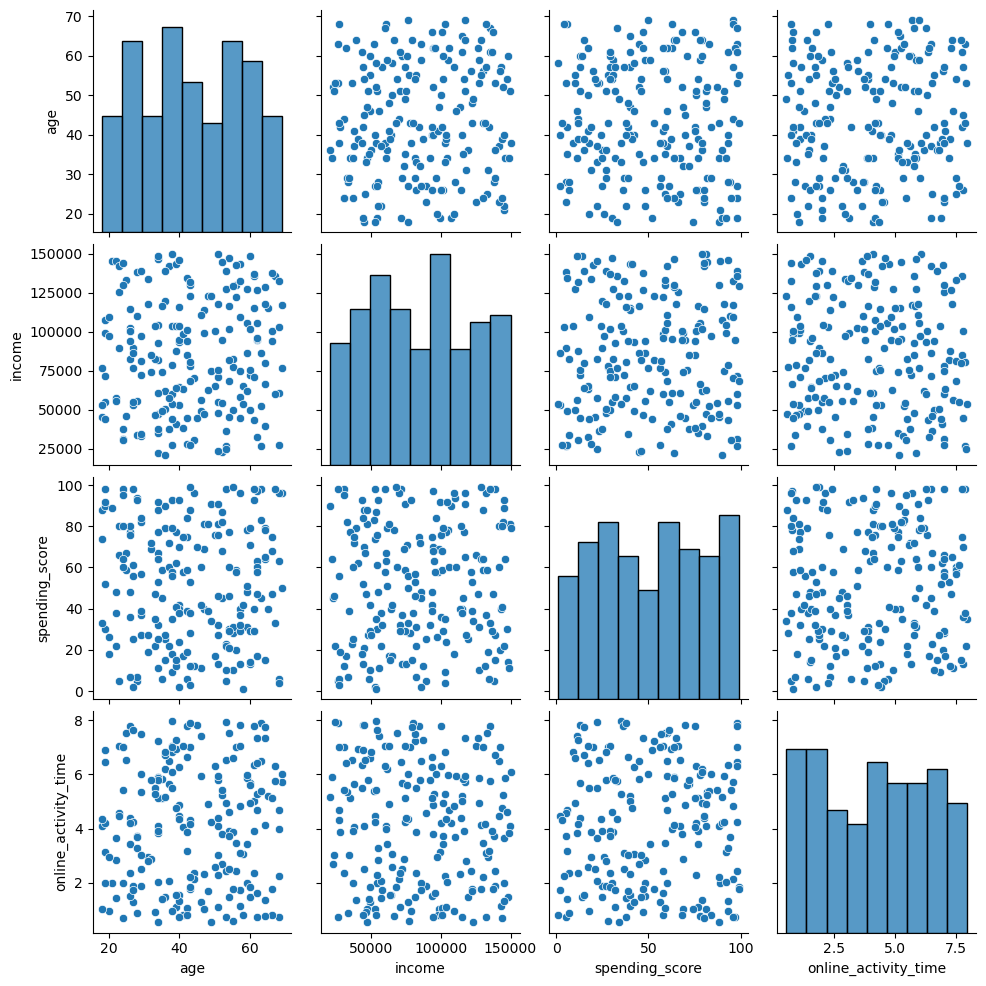

In [7]:
sns.pairplot(df)
plt.savefig('pairplot')
plt.show()

In [8]:
df.columns

Index(['age', 'income', 'spending_score', 'online_activity_time'], dtype='object')

In [9]:
x = df[['age', 'income', 'spending_score', 'online_activity_time']]

In [10]:
# Importing min max scaler
from sklearn.preprocessing import MinMaxScaler
scaler = MinMaxScaler()
x_scale = scaler.fit_transform(x)

In [11]:
# import the model for clustering
from sklearn.cluster import KMeans

In [12]:
# Creating an instance of kmeans
# kmean = KMeans(n_clusters=3)
kmean = KMeans(4)

In [13]:
y_pred = kmean.fit_predict(x_scale)

C:\Users\Daniel\anaconda3\Lib\site-packages\sklearn\cluster\_kmeans.py:1419: UserWarning: KMeans is known to have a memory leak on Windows with MKL, when there are less chunks than available threads. You can avoid it by setting the environment variable OMP_NUM_THREADS=1.
  warnings.warn(


In [14]:
y_pred = kmean.fit_predict(x_scale)
df['cluster'] = y_pred

C:\Users\Daniel\anaconda3\Lib\site-packages\sklearn\cluster\_kmeans.py:1419: UserWarning: KMeans is known to have a memory leak on Windows with MKL, when there are less chunks than available threads. You can avoid it by setting the environment variable OMP_NUM_THREADS=1.
  warnings.warn(


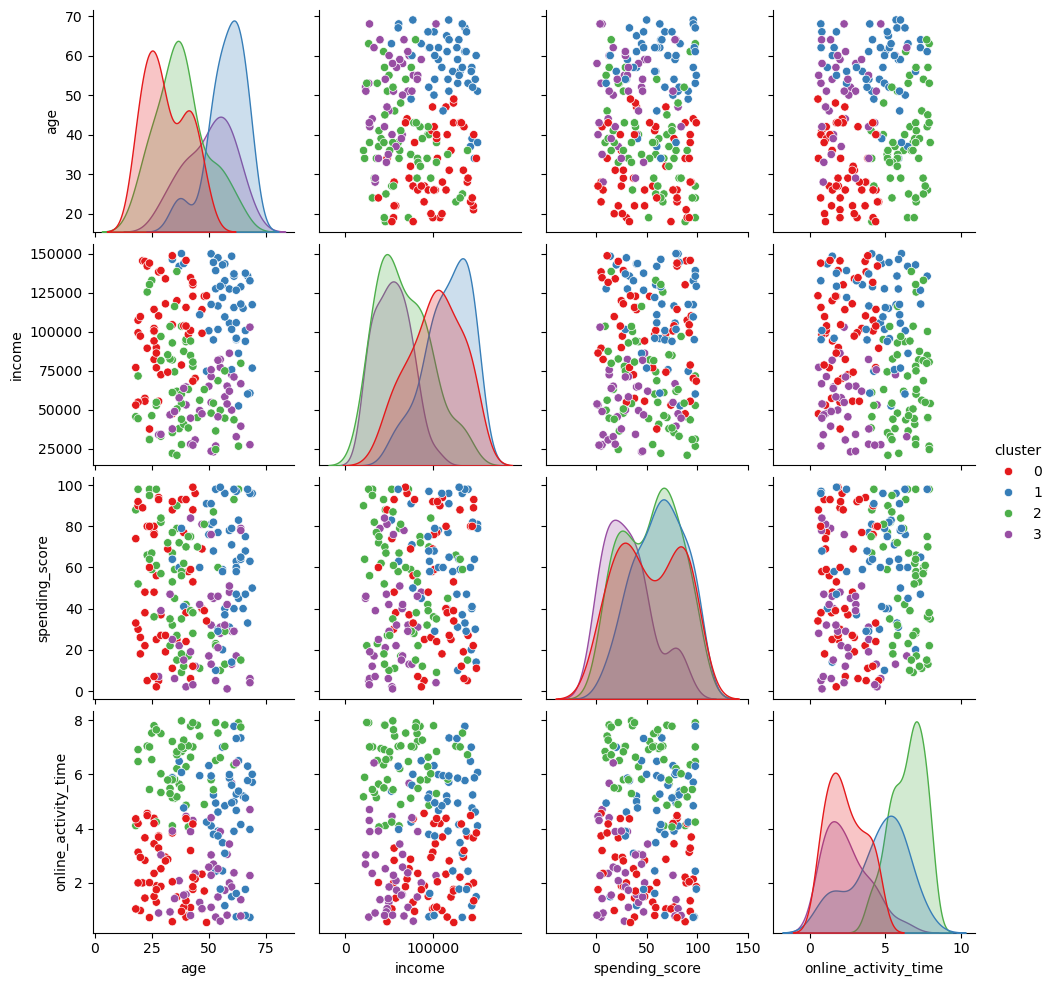

In [15]:
sns.pairplot(df, hue='cluster', palette='Set1',
             vars=['age', 'income', 'spending_score', 'online_activity_time'])
plt.show()

In [16]:
df["target"] = y_pred

In [17]:
df.head()

,age,income,spending_score,online_activity_time,cluster,target
0,27,89768,25,1.89,0,0
1,24,31122,98,7.01,2,2
2,50,100559,76,6.32,1,1
3,40,93543,42,6.28,2,2
4,38,103441,9,6.84,2,2


In [18]:
## if you are Creating an instance of kmeans and you put it as 3 that means this process also has to be three for it to actually work.
df0 = df.loc[df["target"]==0]
df1 = df.loc[df["target"]==1]
df2 = df.loc[df["target"]==2]
df3 = df.loc[df["target"]==3]

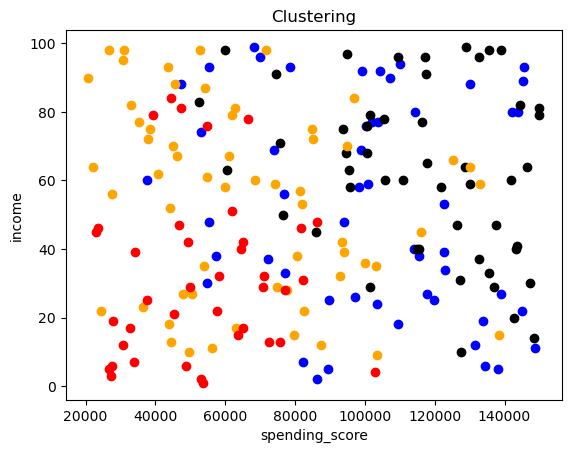

In [19]:
## Why Income vs Spending Score?
## I plotted **Income** against **Spending Score** because both were used to build the clusters, and together they show customer purchasing behavior clearly:
## **Income** shows how much a customer can afford to spend.
## **Spending Score** shows how much the customer actually spends.
plt.scatter(df0["income"], df0["spending_score"], color = "blue")
plt.scatter(df1["income"], df1["spending_score"], color = "black")
plt.scatter(df2["income"], df2["spending_score"], color = "orange")
plt.scatter(df3["income"], df3["spending_score"], color = "red")


plt.title("Clustering")
plt.ylabel("income")
plt.xlabel("spending_score")
plt.savefig('Clustering')
plt.show()

In [20]:
k_rng = range(1,10)

sse = []

for i in k_rng:
    km = KMeans(i)
    km.fit_predict(x_scale)
    sse.append(km.inertia_)
sse    

C:\Users\Daniel\anaconda3\Lib\site-packages\sklearn\cluster\_kmeans.py:1419: UserWarning: KMeans is known to have a memory leak on Windows with MKL, when there are less chunks than available threads. You can avoid it by setting the environment variable OMP_NUM_THREADS=1.
  warnings.warn(
C:\Users\Daniel\anaconda3\Lib\site-packages\sklearn\cluster\_kmeans.py:1419: UserWarning: KMeans is known to have a memory leak on Windows with MKL, when there are less chunks than available threads. You can avoid it by setting the environment variable OMP_NUM_THREADS=1.
  warnings.warn(
C:\Users\Daniel\anaconda3\Lib\site-packages\sklearn\cluster\_kmeans.py:1419: UserWarning: KMeans is known to have a memory leak on Windows with MKL, when there are less chunks than available threads. You can avoid it by setting the environment variable OMP_NUM_THREADS=1.
  warnings.warn(
C:\Users\Daniel\anaconda3\Lib\site-packages\sklearn\cluster\_kmeans.py:1419: UserWarning: KMeans is known to have a memory leak on Wi

[66.675588527322,
 53.99711656856052,
 44.77905128730494,
 37.50179787003867,
 33.59114023971135,
 30.536261840799106,
 27.477908331176906,
 22.81913660813926,
 22.573095992280468]

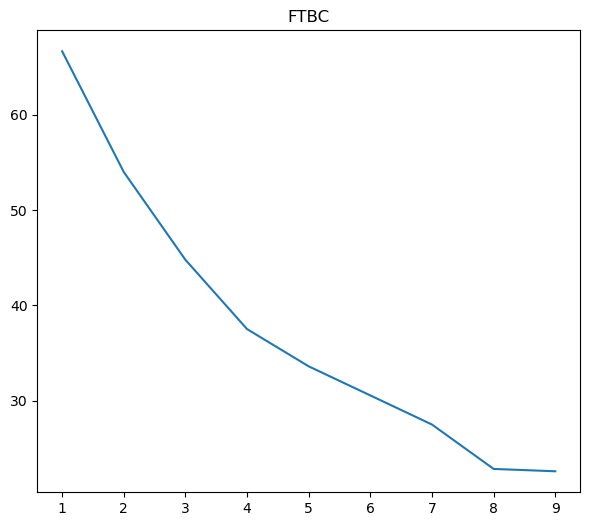

In [21]:
#  The full meaning of (FTBC) is Finding the Best Clusters
plt.figure(figsize = (7,6))
plt.plot(k_rng, sse)
plt.title("FTBC")
plt.savefig('FTBC')
plt.show()